# Descente de gradient à pas variable

Même fonction que dans le notebook précédent. Ici le pas alpha_k est choisi à chaque itération par backtracking avec la condition d'Armijo :

f(x_k - alpha d_k) <= f(x_k) - c * alpha * ||grad f(x_k)||^2

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# fonction de Rosenbrock (meme fonction dans les trois notebooks)
def f(x):
    return (1 - x[0])**2 + 100*(x[1] - x[0]**2)**2

def grad_f(x):
    return np.array([
        -2*(1 - x[0]) - 400*x[0]*(x[1] - x[0]**2),
        200*(x[1] - x[0]**2)
    ])

x0 = np.array([-1.2, 1.0])   # point de depart
x_etoile = np.array([1.0, 1.0])  # minimum connu, f(x*) = 0
tol = 1e-6
max_iter = 50000

In [2]:
def backtracking(x, g, d, alpha0=1.0, rho=0.5, c=1e-4):
    # d est la direction de descente
    alpha = alpha0
    fx = f(x)
    pente = g @ d
    while f(x + alpha*d) > fx + c*alpha*pente:
        alpha *= rho
        if alpha < 1e-16:
            break
    return alpha

def gradient_pas_variable(x0, tol, max_iter):
    x = x0.copy()
    hist_x = [x.copy()]
    hist_f = [f(x)]
    pas = []
    for k in range(max_iter):
        g = grad_f(x)
        if np.linalg.norm(g) < tol:
            break
        d = -g
        alpha = backtracking(x, g, d)
        x = x + alpha * d
        hist_x.append(x.copy())
        hist_f.append(f(x))
        pas.append(alpha)
    return x, k, np.array(hist_x), np.array(hist_f), np.array(pas)

In [3]:
x_fin, nb_iter, hist_x, hist_f, pas = gradient_pas_variable(x0, tol, max_iter)

print("iterations :", nb_iter)
print("x final :", x_fin)
print("f(x final) :", f(x_fin))
print("norme du gradient :", np.linalg.norm(grad_f(x_fin)))

iterations : 13756
x final : [0.99999922 0.99999843]
f(x final) : 6.120021867950454e-13
norme du gradient : 9.833369248479482e-07


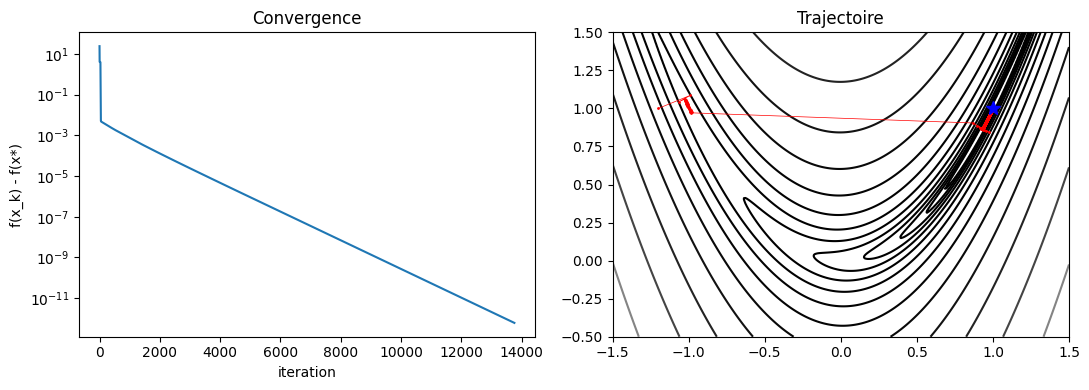

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

ax[0].semilogy(np.maximum(hist_f, 1e-16))
ax[0].set_xlabel("iteration")
ax[0].set_ylabel("f(x_k) - f(x*)")
ax[0].set_title("Convergence")

X, Y = np.meshgrid(np.linspace(-1.5, 1.5, 300), np.linspace(-0.5, 1.5, 300))
Z = (1 - X)**2 + 100*(Y - X**2)**2
ax[1].contour(X, Y, Z, levels=np.logspace(-1, 3, 15), cmap="gray")
ax[1].plot(hist_x[:, 0], hist_x[:, 1], "r.-", lw=0.5, ms=2)
ax[1].plot(*x_etoile, "b*", ms=10)
ax[1].set_title("Trajectoire")

plt.tight_layout()
plt.show()

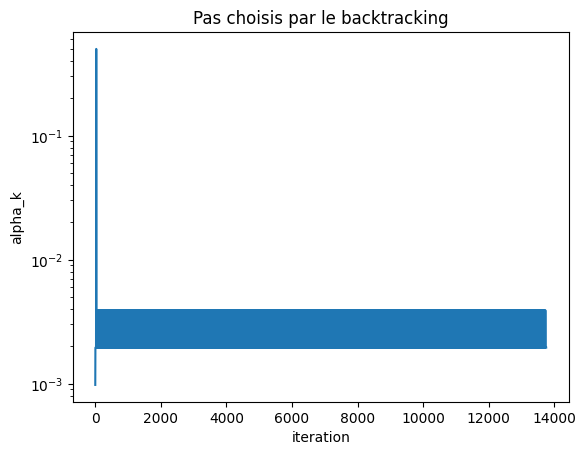

In [5]:
plt.semilogy(pas)
plt.xlabel("iteration")
plt.ylabel("alpha_k")
plt.title("Pas choisis par le backtracking")
plt.show()